# Day 8 - Statistical Baseline Evaluation

Evaluates the three streaming detectors in `src/models/statistical_detector.py`
(**Z-score**, **IQR**, **CUSUM**) and the **UnifiedStatisticalDetector** against ground-truth labels.

**Protocol**
- 6 entities (4 warehouse temperature sensors in 2 zones, 2 vehicle speed signals), 30 s sampling, diurnal cycle + AR(1) noise.
- 3 clean warm-up days (lets hour-of-day baselines learn), then **one scored 24 h day** with injected anomalies:
  *point* spikes, *contextual* (right value, wrong hour) and *collective* (gradual drift ramps).
- Detectors stream the whole series online, in order, with no refits. Only the scored day is evaluated.
- Thresholds are **tuned on seed 0** and **validated on a fresh seed 1** day, so the recommended settings are not graded on the data that chose them.

> The data here is a self-contained simulation that mimics the Day 2/3 simulator signals. To use the real generator,
> replace `make_dataset` with a call that returns the same columns
> (`entity, zone, t, value, label`, with `label` in `normal|point|contextual|collective`).

In [1]:
import sys, time, warnings
from pathlib import Path
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix)

sys.path.insert(0, str(Path.cwd().parent) if Path.cwd().name == "notebooks" else str(Path.cwd()))
from src.models.statistical_detector import (
    ZScoreDetector, IQRDetector, CUSUMDetector, UnifiedStatisticalDetector)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

TYPES = ["point", "contextual", "collective"]
DET = {"z": "Z-score", "iqr": "IQR", "cusum": "CUSUM", "uni": "Unified"}

## 1. Simulated data with injected, labelled anomalies

In [2]:
INTERVAL_S, DAY, WARM_DAYS = 30, 2880, 3          # readings per entity-day = 2880
START = datetime(2026, 3, 2)

ENTITIES = {  # name: (zone, base, diurnal amplitude, noise sd)
    "T-A1": ("A", 4.0, 1.0, 0.30), "T-A2": ("A", 4.5, 0.8, 0.35),
    "T-B1": ("B", 18.0, 1.5, 0.50), "T-B2": ("B", 2.0, 0.6, 0.25),
    "V-01": ("road", 55.0, 12.0, 4.0), "V-02": ("road", 48.0, 10.0, 3.5),
}

def diurnal(amp, hour_float):
    return amp * np.sin(2 * np.pi * (hour_float - 8) / 24)   # peak 14:00, trough 02:00

def make_dataset(seed, n_point=10, n_ctx=5, n_coll=2, ctx_len=12, coll_len=60):
    rng = np.random.default_rng(seed)
    frames = []
    n = (WARM_DAYS + 1) * DAY
    t = np.array([START + timedelta(seconds=INTERVAL_S * i) for i in range(n)])
    hours = (np.arange(n) % DAY) * INTERVAL_S / 3600.0
    for name, (zone, base, amp, sd) in ENTITIES.items():
        e = np.zeros(n); eps = rng.normal(0, 1, n)
        for i in range(1, n):
            e[i] = 0.3 * e[i - 1] + np.sqrt(1 - 0.3 ** 2) * sd * eps[i]
        clean = base + diurnal(amp, hours) + e
        x, label = clean.copy(), np.array(["normal"] * n, dtype=object)
        occupied = np.zeros(n, dtype=bool)
        lo = WARM_DAYS * DAY

        def free(s, L, margin=40):
            return s >= lo + 60 and s + L + margin < n and not occupied[max(0, s - margin): s + L + margin].any()

        def place(kind, L, hour_ranges=None):
            for _ in range(2000):
                s = int(rng.integers(lo + 60, n - L - 50))
                h = hours[s]
                if hour_ranges and not any(a <= h < b for a, b in hour_ranges):
                    continue
                if free(s, L):
                    occupied[s: s + L] = True
                    return s
            raise RuntimeError("could not place anomaly")

        for _ in range(n_ctx):      # opposite-phase level: normal globally, wrong for the hour
            s = place("contextual", ctx_len, [(1, 3.5), (13, 15.5)])
            sl = slice(s, s + ctx_len)
            x[sl] = clean[sl] - 1.6 * diurnal(amp, hours[sl])
            label[sl] = "contextual"
        for _ in range(n_coll):     # gradual ramp to +4 sigma over 30 min
            s = place("collective", coll_len)
            ramp = 4.0 * sd * (np.arange(1, coll_len + 1) / coll_len)
            x[s: s + coll_len] = clean[s: s + coll_len] + ramp
            label[s: s + coll_len] = "collective"
        for _ in range(n_point):    # single-reading spikes, 4-10 sigma
            s = place("point", 1)
            x[s] = clean[s] + rng.choice([-1, 1]) * rng.uniform(4, 10) * sd
            label[s] = "point"
        frames.append(pd.DataFrame({"entity": name, "zone": zone, "t": t, "value": x,
                                    "label": label, "eval": np.arange(n) >= lo}))
    return pd.concat(frames, ignore_index=True)

tune_df, val_df = make_dataset(0), make_dataset(1)
ev = tune_df[tune_df["eval"]]
print(f"scored day: {len(ev):,} readings; anomalous readings = {(ev.label != 'normal').mean():.2%}")
print(ev.label.value_counts().to_string())

scored day: 17,280 readings; anomalous readings = 6.60%
label
normal        16140
collective      720
contextual      360
point            60


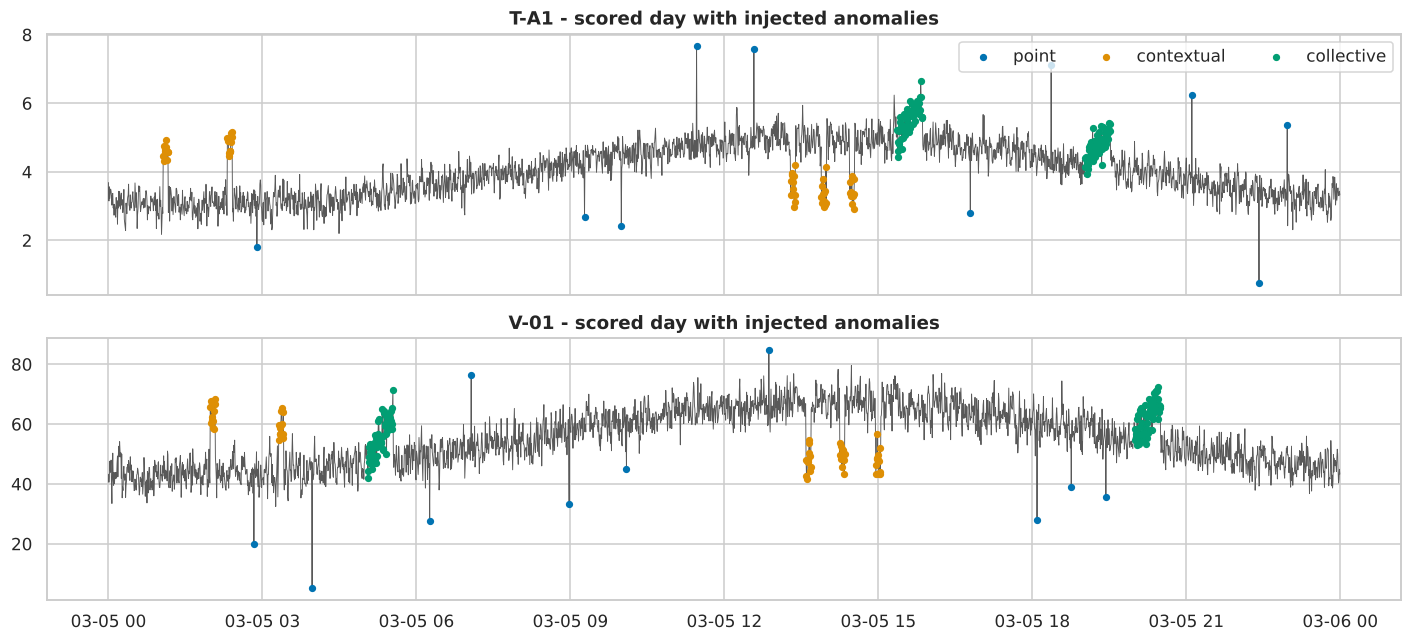

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
for ax, name in zip(axes, ["T-A1", "V-01"]):
    d = ev[ev.entity == name]
    ax.plot(d.t, d.value, lw=0.6, color="0.35")
    for lab, c in zip(TYPES, sns.color_palette("colorblind")[:3]):
        m = d[d.label == lab]
        ax.scatter(m.t, m.value, s=14, color=c, label=lab, zorder=3)
    ax.set_title(f"{name} - scored day with injected anomalies")
axes[0].legend(ncol=3, loc="upper right")
plt.tight_layout(); plt.show()

## 2. Stream the data through the detectors

`UnifiedStatisticalDetector` evaluates all three detectors on every reading and stores each one's `AnomalyScore`,
so one pass gives both the individual and combined results. Score `0.5` is each detector's decision boundary.

**Sections 2-7 use the default settings on purpose** (a baseline); section 8 tunes them and section 10 gives the recommended production settings.

In [4]:
def stream(df, make_unified):
    u = make_unified()
    n = len(df)
    out = {k: np.zeros(n) for k in ["z_score", "z_ratio", "iqr_score", "iqr_ratio",
                                    "cusum_score", "cusum_ratio", "uni_score"]}
    flags = {k: np.zeros(n, dtype=bool) for k in ["z_flag", "iqr_flag", "cusum_flag", "uni_flag"]}
    uni_type = np.empty(n, dtype=object)
    ent, val, tim, zon = df.entity.values, df.value.values, df.t.values, df.zone.values
    order = np.argsort(df.t.values, kind="stable")
    for i in order:
        r = u.detect(ent[i], float(val[i]), pd.Timestamp(tim[i]).to_pydatetime(), zon[i])
        s = r.detector_scores
        out["z_score"][i], out["z_ratio"][i] = s["zscore"].score, s["zscore"].details["ratio"]
        out["iqr_score"][i], out["iqr_ratio"][i] = s["iqr"].score, s["iqr"].details["ratio"]
        out["cusum_score"][i], out["cusum_ratio"][i] = s["cusum"].score, s["cusum"].details["ratio"]
        out["uni_score"][i] = r.severity_score
        flags["z_flag"][i], flags["iqr_flag"][i] = s["zscore"].is_anomaly, s["iqr"].is_anomaly
        flags["cusum_flag"][i], flags["uni_flag"][i] = s["cusum"].is_anomaly, r.is_anomaly
        uni_type[i] = r.anomaly_type
    res = df.copy()
    for k, v in {**out, **flags}.items():
        res[k] = v
    res["uni_type"] = uni_type
    return res

t0 = time.time()
R_all = stream(tune_df, UnifiedStatisticalDetector)
R = R_all[R_all["eval"]].reset_index(drop=True)
print(f"streamed {len(tune_df):,} readings in {time.time()-t0:.1f}s "
      f"({len(tune_df)/(time.time()-t0):,.0f} readings/s, all 3 detectors + merge)")

streamed 69,120 readings in 2.5s (28,130 readings/s, all 3 detectors + merge)


## 3. Metrics per detector and anomaly type

For each anomaly type, positives are the readings of that type and negatives are all *normal* readings
(other anomaly types are excluded from that row). **Precision here is therefore specific to the type**;
`ALL` pools every type. AUC-ROC uses the continuous score; precision/recall/F1 use each detector's own `is_anomaly` decision.

In [5]:
def metrics_table(R, dets=DET):
    rows = []
    for key, nm in dets.items():
        flag = R[f"{key}_flag"].values if key != "uni" else R["uni_flag"].values
        score = R[f"{key}_score"].values
        for typ in TYPES + ["ALL"]:
            m = (R.label == "normal") | ((R.label != "normal") if typ == "ALL" else (R.label == typ))
            y = (R.label[m] != "normal").values
            p = flag[m]
            rows.append(dict(detector=nm, type=typ, n_pos=int(y.sum()),
                             precision=precision_score(y, p, zero_division=0),
                             recall=recall_score(y, p, zero_division=0),
                             f1=f1_score(y, p, zero_division=0),
                             auc=roc_auc_score(y, score[m])))
    return pd.DataFrame(rows)

M = metrics_table(R)
pd.options.display.float_format = "{:.3f}".format
M.pivot(index="detector", columns="type", values=["precision", "recall", "f1", "auc"])\
 .reindex([*DET.values()])

precision                             recall                        \
type           ALL collective contextual point    ALL collective contextual   
detector                                                                      
Z-score      0.889      0.707      0.826 0.464  0.472      0.225      0.883   
IQR          0.991      0.939      0.987 0.946  0.289      0.064      0.642   
CUSUM        0.397      0.281      0.197 0.021  0.742      0.697      0.878   
Unified      0.403      0.273      0.203 0.041  0.795      0.701      0.953   

                  f1                               auc                        \
type     point   ALL collective contextual point   ALL collective contextual   
detector                                                                       
Z-score  0.967 0.617      0.341      0.854 0.627 0.856      0.776      0.993   
IQR      0.883 0.448      0.120      0.778 0.914 0.837      0.748      0.987   
CUSUM    0.467 0.517      0.400      0.322 0.041 0.901      0.872      0.954   
Unified  0.967 0.535      0.393      0.335 0.079 0.903      0.854      0.987   

                
type     point  
detector        
Z-score  1.000  
IQR      0.999  
CUSUM    0.933  
Unified  0.996

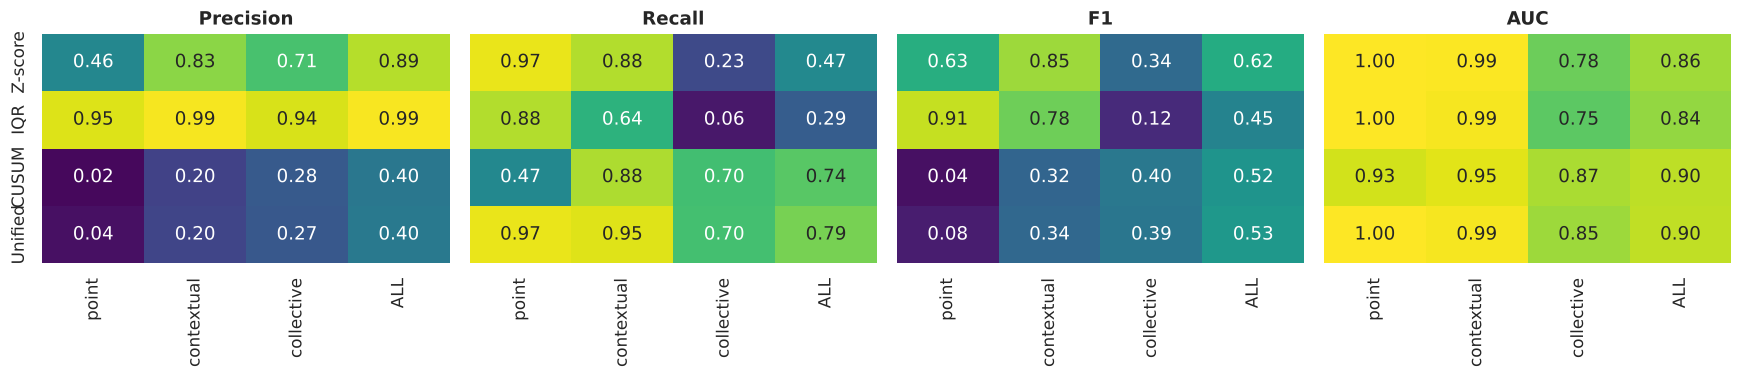

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, met in zip(axes, ["precision", "recall", "f1", "auc"]):
    piv = M.pivot(index="detector", columns="type", values=met).reindex(list(DET.values()))[TYPES + ["ALL"]]
    sns.heatmap(piv, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1, cbar=False, ax=ax)
    ax.set_title(met.upper() if met == "auc" else met.capitalize()); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

### Event-level view (what an operator experiences)

Point-wise recall under-credits drift detection: a 30-minute ramp is only clearly abnormal at the end, but catching it
*early* is the goal. An event counts as **detected** if the detector fires inside the event or within 10 readings after it.
`delay` is minutes from event start to first flag. **False-alarm incidents** are contiguous flag runs not near any true event.

In [7]:
TOL = 10

def events(R):
    out = []
    for ent, d in R.groupby("entity", sort=False):
        lab = d.label.values; i = 0
        while i < len(lab):
            if lab[i] != "normal":
                j = i
                while j + 1 < len(lab) and lab[j + 1] == lab[i]: j += 1
                out.append((ent, lab[i], d.index[i], d.index[j])); i = j + 1
            else:
                i += 1
    return out

def event_table(R, dets=DET):
    ev_list = events(R); rows = []
    for key, nm in dets.items():
        f = R[f"{key}_flag"].values
        for typ in TYPES:
            sel = [e for e in ev_list if e[1] == typ]
            det, delays = 0, []
            for ent, _, a, b in sel:
                w = f[a: b + 1 + TOL]
                if w.any():
                    det += 1; delays.append(int(np.argmax(w)) * INTERVAL_S / 60)
            rows.append(dict(detector=nm, type=typ, events=len(sel), detected=det / len(sel),
                             median_delay_min=np.median(delays) if delays else np.nan))
        # false-alarm incidents: flag runs not within TOL of any true anomaly
        fa = 0
        for ent, d in R.groupby("entity", sort=False):
            ff, lab = f[d.index], (d.label.values != "normal")
            near = np.convolve(lab.astype(int), np.ones(2 * TOL + 1), mode="same") > 0
            bad = ff & ~near
            fa += int(((bad[1:] & ~bad[:-1]).sum()) + bad[0])
        rows.append(dict(detector=nm, type="false alarms / entity-day", events=np.nan,
                         detected=np.nan, median_delay_min=fa / R.entity.nunique()))
    return pd.DataFrame(rows)

E = event_table(R)
E[E.type != "false alarms / entity-day"].pivot(index="detector", columns="type",
    values=["detected", "median_delay_min"]).reindex(list(DET.values()))

detected                  median_delay_min                 
type     collective contextual point       collective contextual point
detector                                                              
Z-score       1.000      1.000 0.967           12.250      0.000 0.000
IQR           0.833      0.967 0.883           22.000      0.500 0.000
CUSUM         1.000      1.000 0.567            8.750      0.500 0.000
Unified       1.000      1.000 0.967            7.750      0.000 0.000

In [8]:
print("False-alarm incidents per entity per day (lower is better):")
E[E.type == "false alarms / entity-day"].set_index("detector")[["median_delay_min"]]\
 .rename(columns={"median_delay_min": "FA incidents / entity-day"}).reindex(list(DET.values()))

False-alarm incidents per entity per day (lower is better):


,FA incidents / entity-day
detector,
Z-score,8.500
IQR,0.333
CUSUM,9.500
Unified,16.667


## 4. Confusion matrices (anomaly vs normal, all types pooled)

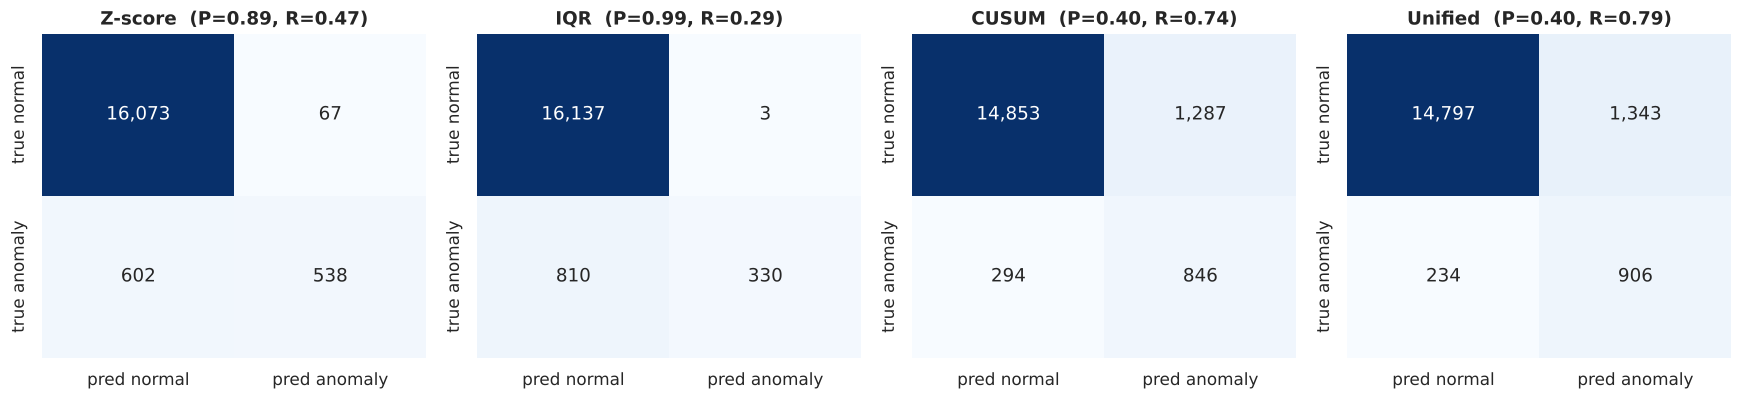

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
y = (R.label != "normal").values
for ax, (key, nm) in zip(axes, DET.items()):
    cm = confusion_matrix(y, R[f"{key}_flag"].values, labels=[False, True])
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["pred normal", "pred anomaly"], yticklabels=["true normal", "true anomaly"])
    ax.set_title(f"{nm}  (P={precision_score(y, R[f'{key}_flag'], zero_division=0):.2f}, "
                 f"R={recall_score(y, R[f'{key}_flag'], zero_division=0):.2f})")
plt.tight_layout(); plt.show()

## 5. Score distributions by true anomaly type

The dashed line at 0.5 is the decision boundary. Good separation = anomaly curves sit right of the line while *normal* stays left.

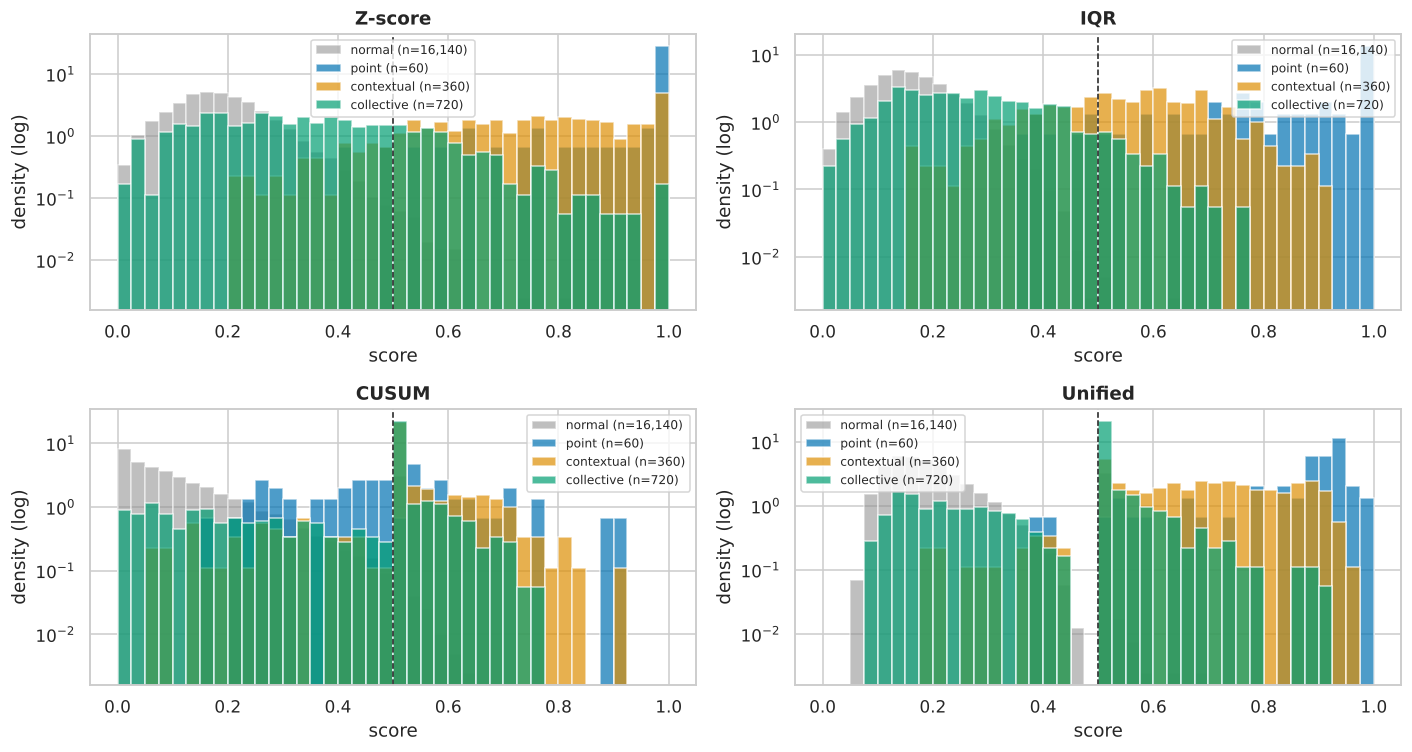

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
pal = dict(zip(["normal"] + TYPES, ["0.55"] + sns.color_palette("colorblind")[:3]))
for ax, (key, nm) in zip(axes.ravel(), DET.items()):
    for lab in ["normal"] + TYPES:
        s = R.loc[R.label == lab, f"{key}_score"]
        ax.hist(s, bins=np.linspace(0, 1, 41), density=True, alpha=0.55 if lab == "normal" else 0.7,
                color=pal[lab], label=f"{lab} (n={len(s):,})")
    ax.axvline(0.5, ls="--", color="k", lw=1)
    ax.set_yscale("log"); ax.set_title(nm); ax.set_xlabel("score"); ax.set_ylabel("density (log)")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6. ROC curves per anomaly type

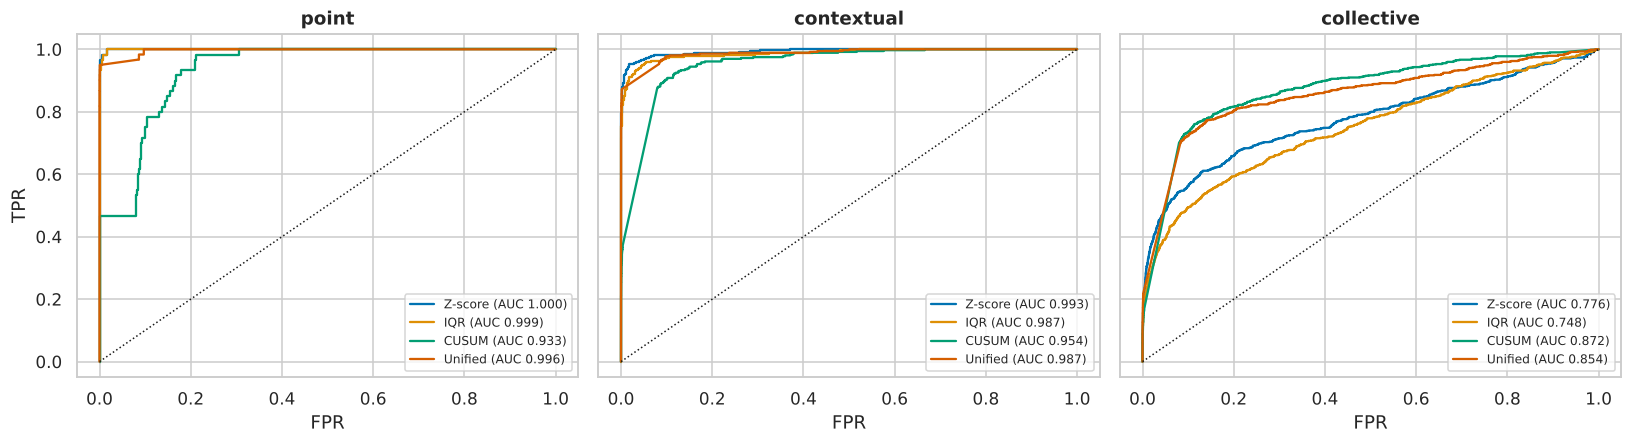

In [11]:
from sklearn.metrics import roc_curve
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, typ in zip(axes, TYPES):
    m = (R.label == "normal") | (R.label == typ); y = (R.label[m] == typ).values
    for key, nm in DET.items():
        fpr, tpr, _ = roc_curve(y, R.loc[m, f"{key}_score"])
        ax.plot(fpr, tpr, label=f"{nm} (AUC {roc_auc_score(y, R.loc[m, f'{key}_score']):.3f})")
    ax.plot([0, 1], [0, 1], "k:", lw=1); ax.set_title(typ); ax.set_xlabel("FPR"); ax.legend(fontsize=8, loc="lower right")
axes[0].set_ylabel("TPR")
plt.tight_layout(); plt.show()

## 7. One entity over the scored day

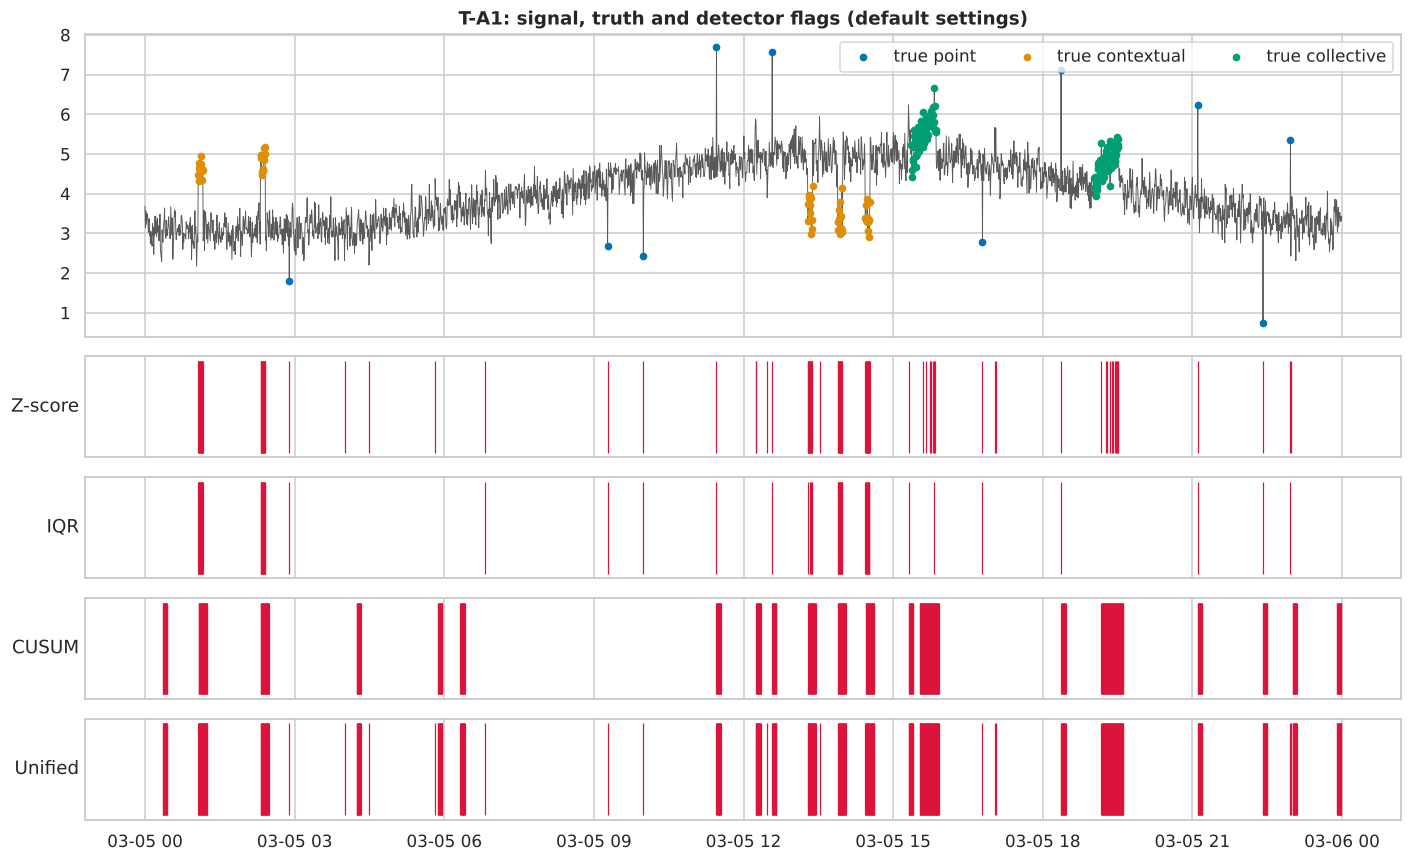

In [12]:
d = R[R.entity == "T-A1"]
fig, ax = plt.subplots(5, 1, figsize=(13, 8), sharex=True, gridspec_kw=dict(height_ratios=[3, 1, 1, 1, 1]))
ax[0].plot(d.t, d.value, lw=0.6, color="0.35")
for lab, c in zip(TYPES, sns.color_palette("colorblind")[:3]):
    m = d[d.label == lab]; ax[0].scatter(m.t, m.value, s=16, color=c, label=f"true {lab}", zorder=3)
ax[0].legend(ncol=3, loc="upper right"); ax[0].set_title("T-A1: signal, truth and detector flags (default settings)")
for a, (key, nm) in zip(ax[1:], DET.items()):
    f = d[d[f"{key}_flag"]]
    a.vlines(f.t, 0, 1, color="crimson", lw=0.8); a.set_yticks([]); a.set_ylabel(nm, rotation=0, ha="right", va="center")
plt.tight_layout(); plt.show()

## 8. Threshold tuning and optimal production settings

Each detector is re-run (standalone, same code path as in the unified detector) over a grid on the **tuning day (seed 0)**,
choosing the setting with the best pooled F1. The chosen setting is then scored on the **validation day (seed 1)**.

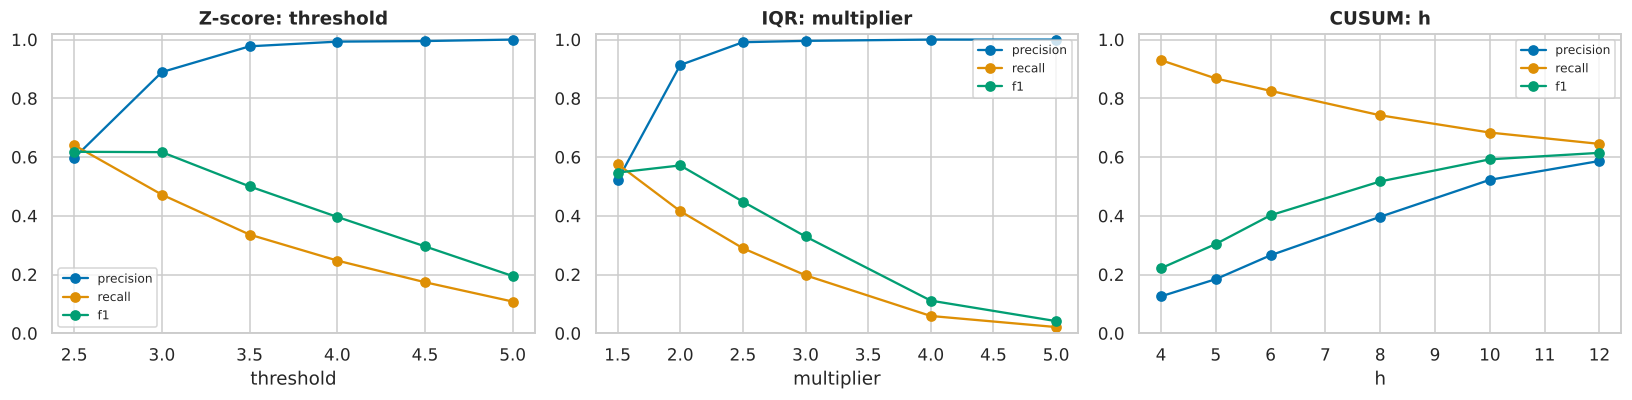

--- z
 threshold  precision  recall    f1  event_recall  fa_per_entity_day
     2.500      0.597   0.640 0.618         1.000             63.167
     3.000      0.889   0.472 0.617         0.980              8.500
     3.500      0.977   0.336 0.500         0.961              1.333
     4.000      0.993   0.247 0.396         0.863              0.167
     4.500      0.995   0.174 0.296         0.784              0.167
     5.000      1.000   0.108 0.195         0.637              0.000
--- iqr
 multiplier  precision  recall    f1  event_recall  fa_per_entity_day
      1.500      0.521   0.576 0.547         1.000             72.833
      2.000      0.913   0.416 0.571         0.971              5.833
      2.500      0.991   0.289 0.448         0.902              0.333
      3.000      0.996   0.197 0.329         0.833              0.167
      4.000      1.000   0.059 0.111         0.520              0.000
      5.000      1.000   0.021 0.041         0.235              0.000
--- cusum
 h 

In [13]:
def run_single(df, make):
    det = make()
    flag = np.zeros(len(df), dtype=bool)
    ent, val, tim, zon = df.entity.values, df.value.values, df.t.values, df.zone.values
    for i in np.argsort(tim, kind="stable"):
        flag[i] = det.update(ent[i], float(val[i]), pd.Timestamp(tim[i]).to_pydatetime(), zon[i]).is_anomaly
    return flag

def summarize(df, flag):
    m = df["eval"].values
    y = (df.label.values[m] != "normal"); p = flag[m]
    sub = df[m].reset_index(drop=True).assign(f=p)
    ev_list = events(sub.assign(label=sub.label)); det = np.mean([sub.f.values[a: b + 1 + TOL].any() for _, _, a, b in ev_list])
    fa = 0
    for ent, d in sub.groupby("entity", sort=False):
        ff, lab = d.f.values, (d.label.values != "normal")
        near = np.convolve(lab.astype(int), np.ones(2 * TOL + 1), mode="same") > 0
        bad = ff & ~near; fa += int(((bad[1:] & ~bad[:-1]).sum()) + bad[0])
    return dict(precision=precision_score(y, p, zero_division=0), recall=recall_score(y, p, zero_division=0),
                f1=f1_score(y, p, zero_division=0), event_recall=det, fa_per_entity_day=fa / sub.entity.nunique())

GRIDS = {
    "z": ("threshold", [2.5, 3.0, 3.5, 4.0, 4.5, 5.0], lambda v: (lambda: ZScoreDetector(threshold=v))),
    "iqr":    ("multiplier", [1.5, 2.0, 2.5, 3.0, 4.0, 5.0], lambda v: (lambda: IQRDetector(multiplier=v))),
    "cusum":  ("h", [4, 5, 6, 8, 10, 12], lambda v: (lambda: CUSUMDetector(h=v))),
}
sweeps = {}
for nm, (param, vals, mk) in GRIDS.items():
    rows = [dict(**{param: v}, **summarize(tune_df, run_single(tune_df, mk(v)))) for v in vals]
    sweeps[nm] = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (nm, df_) in zip(axes, sweeps.items()):
    p = df_.columns[0]
    for c in ["precision", "recall", "f1"]:
        ax.plot(df_[p], df_[c], marker="o", label=c)
    ax.set_title(f"{DET[nm]}: {p}"); ax.set_xlabel(p); ax.set_ylim(0, 1.02); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
for nm, df_ in sweeps.items():
    print(f"--- {nm}"); print(df_.round(3).to_string(index=False))

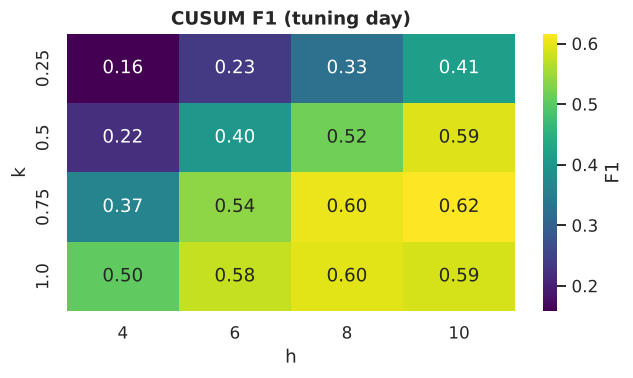

In [14]:
# CUSUM slack k jointly with h
rows = []
for k in [0.25, 0.5, 0.75, 1.0]:
    for h in [4, 6, 8, 10]:
        rows.append(dict(k=k, h=h, **summarize(tune_df, run_single(tune_df, lambda: CUSUMDetector(k=k, h=h)))))
CK = pd.DataFrame(rows)
plt.figure(figsize=(6, 3.6))
sns.heatmap(CK.pivot(index="k", columns="h", values="f1"), annot=True, fmt=".2f", cmap="viridis", cbar_kws=dict(label="F1"))
plt.title("CUSUM F1 (tuning day)"); plt.tight_layout(); plt.show()

In [15]:
FA_BUDGET = 3.0   # max false-alarm incidents per entity per day an operator will tolerate

def pick(df_):
    ok = df_[df_.fa_per_entity_day <= FA_BUDGET]
    if ok.empty:
        return df_.sort_values("fa_per_entity_day").iloc[0]
    return ok.sort_values(["f1", "event_recall"], ascending=False).iloc[0]

best = {nm: pick(sweeps[nm]).iloc[0] for nm in GRIDS}
bk = pick(CK)
best["cusum_k"], best["cusum_h"] = float(bk.k), float(bk.h)
print("Best on tuning day:", {k: round(float(v), 2) for k, v in best.items()})

def tuned_unified(vote=0.25):
    return UnifiedStatisticalDetector(
        zscore=ZScoreDetector(threshold=float(best["z"])),
        iqr=IQRDetector(multiplier=float(best["iqr"])),
        cusum=CUSUMDetector(k=best["cusum_k"], h=best["cusum_h"]), vote_threshold=vote)

cfgs = {"defaults": UnifiedStatisticalDetector}
for v in (0.25, 0.4, 0.6, 0.8):
    cfgs[f"tuned, vote>={v}"] = (lambda v=v: tuned_unified(v))
rows = []
for name, mk in cfgs.items():
    for dname, df_ in (("tune (seed 0)", tune_df), ("VALIDATION (seed 1)", val_df)):
        Rr = stream(df_, mk); Re = Rr[Rr["eval"]].reset_index(drop=True)
        y = (Re.label != "normal").values; p = Re.uni_flag.values
        et = event_table(Re); evd = et[et.type.isin(TYPES)].set_index("type").detected
        fa = et[(et.detector == "Unified") & (et.type == "false alarms / entity-day")].median_delay_min.iloc[0]
        rows.append(dict(config=name, data=dname, precision=precision_score(y, p, zero_division=0),
                         recall=recall_score(y, p, zero_division=0), f1=f1_score(y, p, zero_division=0),
                         point_evt=evd.loc[evd.index.isin(TYPES)].iloc[0] if False else et[(et.detector=="Unified")&(et.type=="point")].detected.iloc[0],
                         ctx_evt=et[(et.detector=="Unified")&(et.type=="contextual")].detected.iloc[0],
                         coll_evt=et[(et.detector=="Unified")&(et.type=="collective")].detected.iloc[0],
                         fa_per_entity_day=fa))
CMP = pd.DataFrame(rows)
CMP.round(3)

Best on tuning day: {'z': 3.5, 'iqr': 2.5, 'cusum': 12.0, 'cusum_k': 0.75, 'cusum_h': 10.0}


,config,data,precision,recall,f1,point_evt,ctx_evt,coll_evt,fa_per_entity_day
0,defaults,tune (seed 0),0.403,0.795,0.535,0.967,1.000,1.000,16.667
1,defaults,VALIDATION (seed 1),0.427,0.802,0.557,1.000,1.000,1.000,18.000
2,"tuned, vote>=0.25",tune (seed 0),0.649,0.702,0.674,0.950,1.000,1.000,1.833
3,"tuned, vote>=0.25",VALIDATION (seed 1),0.648,0.713,0.679,0.983,1.000,1.000,2.833
4,"tuned, vote>=0.4",tune (seed 0),0.977,0.340,0.505,0.950,1.000,1.000,1.333
5,"tuned, vote>=0.4",VALIDATION (seed 1),0.974,0.390,0.557,0.983,1.000,1.000,1.667
6,"tuned, vote>=0.6",tune (seed 0),0.995,0.328,0.493,0.883,0.967,1.000,0.167
7,"tuned, vote>=0.6",VALIDATION (seed 1),0.995,0.378,0.548,0.983,1.000,1.000,0.333
8,"tuned, vote>=0.8",tune (seed 0),1.000,0.206,0.342,0.050,0.967,0.750,0.000
9,"tuned, vote>=0.8",VALIDATION (seed 1),1.000,0.218,0.357,0.033,1.000,1.000,0.000


In [16]:
# Individual detectors at tuned vs default settings, on the held-out validation day
rows = []
for nm, mk_def, mk_tun in [
    ("z", lambda: ZScoreDetector(), lambda: ZScoreDetector(threshold=float(best["z"]))),
    ("iqr", lambda: IQRDetector(), lambda: IQRDetector(multiplier=float(best["iqr"]))),
    ("cusum", lambda: CUSUMDetector(), lambda: CUSUMDetector(k=best["cusum_k"], h=best["cusum_h"])),
]:
    for tag, mk in (("default", mk_def), ("tuned", mk_tun)):
        rows.append(dict(detector=DET[nm], setting=tag, **summarize(val_df, run_single(val_df, mk))))
pd.DataFrame(rows).round(3)

,detector,setting,precision,recall,f1,event_recall,fa_per_entity_day
0,Z-score,default,0.891,0.489,0.632,1.000,10.000
1,Z-score,tuned,0.972,0.367,0.532,0.990,1.667
2,IQR,default,0.990,0.332,0.497,0.990,0.667
3,IQR,tuned,0.990,0.332,0.497,0.990,0.667
4,CUSUM,default,0.418,0.733,0.533,0.686,8.667
5,CUSUM,tuned,0.619,0.611,0.615,0.461,0.833


### Why CUSUM is seasonal by default

Plain CUSUM standardises against one global baseline, so a daily cycle looks like a permanent drift.
`CUSUMDetector(seasonal=True)` standardises against an interpolated hour-of-day baseline instead.

In [17]:
rows = []
for seasonal in (False, True):
    flag = run_single(tune_df, lambda: CUSUMDetector(seasonal=seasonal))
    rows.append(dict(cusum_seasonal=seasonal, **summarize(tune_df, flag)))
pd.DataFrame(rows).round(3)

,cusum_seasonal,precision,recall,f1,event_recall,fa_per_entity_day
0,False,0.083,0.931,0.153,0.971,30.000
1,True,0.397,0.742,0.517,0.745,9.500


## 9. Throughput

In [18]:
sample = tune_df.iloc[:60000]
for nm, mk in [("zscore", ZScoreDetector), ("iqr", IQRDetector), ("cusum", CUSUMDetector), ("unified", UnifiedStatisticalDetector)]:
    t0 = time.time(); u = mk(); fn = u.detect if nm == "unified" else u.update
    for e, v, t, z in zip(sample.entity.values, sample.value.values, sample.t.values, sample.zone.values):
        fn(e, float(v), pd.Timestamp(t).to_pydatetime(), z)
    dt = time.time() - t0
    print(f"{nm:8s} {len(sample)/dt:>10,.0f} readings/s   {1e6*dt/len(sample):6.1f} us/reading")

zscore      196,471 readings/s      5.1 us/reading


iqr          96,499 readings/s     10.4 us/reading


cusum       220,440 readings/s      4.5 us/reading


unified      27,622 readings/s     36.2 us/reading


In [19]:
FINAL = dict(
    zscore=dict(threshold=float(best["z"]), contextual=True, min_samples=30),
    iqr=dict(window=1000, multiplier=float(best["iqr"]), bucket_hours=1),
    cusum=dict(k=best["cusum_k"], h=best["cusum_h"], cooldown_readings=10),
)
import json; print(json.dumps(FINAL, indent=2))

{
  "zscore": {
    "threshold": 3.5,
    "contextual": true,
    "min_samples": 30
  },
  "iqr": {
    "window": 1000,
    "multiplier": 2.5,
    "bucket_hours": 1
  },
  "cusum": {
    "k": 0.75,
    "h": 10.0,
    "cooldown_readings": 10
  }
}


## 10. Findings and recommended production settings

Numbers below come from the **validation day (seed 1)** unless stated; they are from simulated data, so treat them as relative
guidance and re-tune on real traffic.

**Recommended configuration** (`UnifiedStatisticalDetector.production()`):

| Detector | Setting | Why |
|---|---|---|
| Z-score | `threshold=3.5`, `contextual=True` | 3.0 gave ~10 false-alarm incidents per entity-day; 3.5 keeps ~1.7 with event recall 0.99 |
| IQR | `multiplier=2.5`, `window=1000`, hourly bins | Highest precision (0.99); default is already the best setting under the false-alarm budget |
| CUSUM | `k=0.75`, `h=10`, `cooldown=10`, `seasonal=True` | Seasonal baseline is essential (30 -> 9.5 false-alarm incidents at default h); larger k/h trades delay for quiet |
| Unified | weights 0.4/0.3/0.3, `vote_threshold=0.25` (any detector) | F1 0.68, precision 0.65, recall 0.71, 2.8 false-alarm incidents per entity-day, 100% of contextual and collective events detected |

**What each detector is good for**
- **Z-score**: best all-rounder for point anomalies; the hour-of-day baseline is what makes it catch *contextual* anomalies (AUC 0.99). Weak on slow drift on its own.
- **IQR**: very few false alarms, but conservative: low recall on drift (0.06) and slowest to react. Good as a "confirm" signal.
- **CUSUM**: the only detector with real drift sensitivity (collective AUC 0.87-0.95, median delay under 10 min for a 30-min ramp). It cannot catch single-reading spikes and its alarms are held for the cooldown, which costs point-wise precision.
- **Unified**: the OR vote keeps the union of what the three catch, and the 3.5/2.5/10 tuning removes most of the noise that dominates the defaults (F1 0.56 -> 0.68). Raising `vote_threshold` to 0.4+ requires agreement from two detectors and makes it very precise (0.97) but misses roughly 60% of anomalous readings, so use it only for paging-level alerts.

**Caveats**
- Point-wise F1 is capped because drift ramps are only clearly abnormal near their end; use the event-level table (detection rate and delay) for drift.
- CUSUM and the contextual Z-score need history: ~15 min per hour-bucket for CUSUM and `min_context_samples` per hour for Z. In a cold start, expect reduced contextual and drift sensitivity for the first day.
- Tuning and validation use the same simulator with different seeds, so they check for overfitting to a seed, not to the simulator. Re-run section 8 on real data.